##### 07 · Perfis municipais e prioridades territoriais

Este notebook transforma os segmentos numéricos em perfis interpretáveis e responde à parte aplicada do Tech Challenge:

- quais municípios compartilham condições semelhantes;
- onde esses perfis estão distribuídos;
- quais perfis concentram maior risco de não atingir a meta.

O notebook não refaz o agrupamento. Ele reutiliza os artefatos do notebook anterior, ficando mais leve para executar.


In [7]:
from pathlib import Path
import os
import sys
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42


def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "src").exists():
            return candidato
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


PROJECT_ROOT = localizar_raiz()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
REPORTS = PROJECT_ROOT / "reports"
IMAGES = PROJECT_ROOT / "images"
REPORTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)

from src.visualization.plot_style import (
    aplicar_estilo,
    salvar_figura,
    AZUL,
    LARANJA,
    VERDE,
    VERMELHO,
    CINZA,
    PALETA,
)
from src.visualization.business_labels import rotulo, rotular

aplicar_estilo()
pd.set_option("display.max_columns",100)
pd.set_option("display.width",180)

ARQ_MUNICIPIO = PROCESSED / "base_analitica_municipio.parquet"
if not ARQ_MUNICIPIO.exists():
    raise FileNotFoundError(ARQ_MUNICIPIO)

abt = pd.read_parquet(ARQ_MUNICIPIO)
abt["ano_alvo"] = pd.to_numeric(abt["ano_alvo"], errors="coerce").astype("Int64")
print(f"Base municipal: {abt.shape}")


Base municipal: (43788, 59)


##### 1. Carregamento da segmentação


In [8]:
ARTEFATO_PATH = MODELS / "segmentacao_municipios.joblib"
SEGMENTACAO_PATH = REPORTS / "segmentacao_municipios.parquet"

if not ARTEFATO_PATH.exists() or not SEGMENTACAO_PATH.exists():
    raise FileNotFoundError("Execute primeiro o notebook 06 de segmentação.")

artefato = joblib.load(ARTEFATO_PATH)
segmentacao = pd.read_parquet(SEGMENTACAO_PATH)
ANO_RETRATO = int(artefato["ano_retrato"])
variaveis = list(artefato["features"])
LOG_VARS = list(artefato["log_features"])
preprocessador = artefato["preprocessador"]
modelo_segmentacao = artefato["modelo"]

base = abt[abt["ano_alvo"].eq(ANO_RETRATO)].copy()
if "rede" in base.columns and "rede" in segmentacao.columns:
    rede_texto = base["rede"].astype("string").str.lower().str.strip()
    municipal = base[rede_texto.eq("municipal")].copy()
    if not municipal.empty:
        base = municipal
base = base.sort_values("id_municipio").drop_duplicates("id_municipio", keep="last")
base = base.merge(segmentacao[["id_municipio","segmento"]], on="id_municipio", how="inner")

print(f"Ano do retrato: {ANO_RETRATO}")
print(f"Municípios segmentados: {len(base):,}")
print(f"Segmentos: {base['segmento'].nunique()}")


Ano do retrato: 2030
Municípios segmentados: 5,477
Segmentos: 2


##### 2. Assinatura dos segmentos


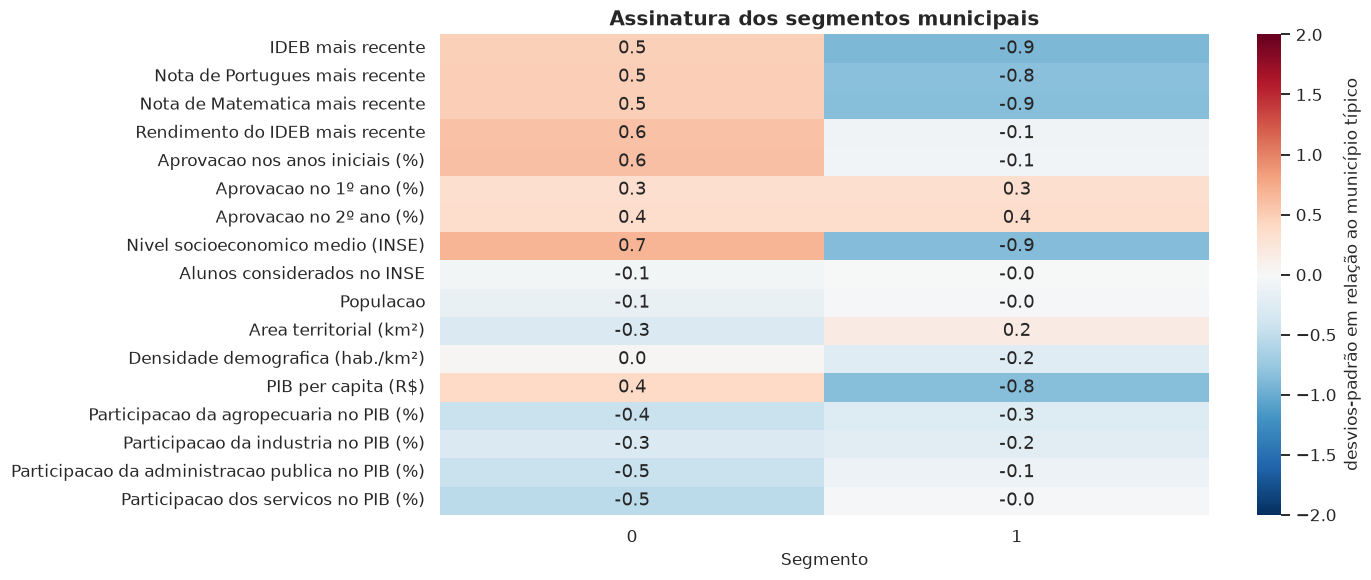

segmento,0,1
ideb_ideb_observado_ultimo,6.6,5.4
ideb_ideb_nota_portugues_ultimo,226.11,198.85
ideb_ideb_nota_matematica_ultimo,241.95,209.48
ideb_ideb_rendimento_ultimo,1.0,0.98
ideb_aprovacao_ai_pct_ultimo,99.8,98.2
ideb_aprovacao_1ano_pct_ultimo,100.0,100.0
ideb_aprovacao_2ano_pct_ultimo,100.0,100.0
media_inse,5.17,4.4
qtd_alunos_inse,159.0,170.0
populacao,10675.5,12251.0


In [9]:
perfil = base.groupby("segmento")[variaveis].median(numeric_only=True)
perfil_transformado = perfil.copy()
for coluna in LOG_VARS:
    perfil_transformado[coluna] = np.log1p(perfil_transformado[coluna].clip(lower=0))

perfil_z = pd.DataFrame(
    preprocessador.transform(perfil_transformado),
    index=perfil.index,
    columns=rotular(variaveis),
)

fig, ax = plt.subplots(figsize=(13, max(5, len(variaveis)*0.32)))
sns.heatmap(
    perfil_z.T,
    cmap="RdBu_r",
    center=0,
    vmin=-2,
    vmax=2,
    annot=True,
    fmt=".1f",
    ax=ax,
    cbar_kws={"label":"desvios-padrão em relação ao município típico"},
)
ax.set_xlabel("Segmento")
ax.set_ylabel("")
ax.set_title("Assinatura dos segmentos municipais")
salvar_figura(fig, "07_assinatura_segmentos")
plt.show()

display(perfil.round(2).T)


##### 3. Nomes descritivos gerados a partir dos dados


In [10]:
# Os nomes são deliberadamente descritivos e dependem das variáveis existentes.
def nomear_segmento(linha, referencia):
    partes = []

    if "indicador_t1" in linha.index:
        partes.append("resultado recente alto" if linha["indicador_t1"] >= referencia["indicador_t1"] else "resultado recente baixo")

    if "ideb_ideb_observado_ultimo" in linha.index:
        partes.append("IDEB alto" if linha["ideb_ideb_observado_ultimo"] >= referencia["ideb_ideb_observado_ultimo"] else "IDEB baixo")

    if "media_inse" in linha.index:
        partes.append("INSE alto" if linha["media_inse"] >= referencia["media_inse"] else "INSE baixo")

    if "populacao" in linha.index:
        partes.append("maior porte" if linha["populacao"] >= referencia["populacao"] else "menor porte")

    return ", ".join(partes[:3]).capitalize()

referencia = base[variaveis].median(numeric_only=True)
nomes = {segmento:nomear_segmento(perfil.loc[segmento], referencia) for segmento in perfil.index}
base["perfil_municipal"] = base["segmento"].map(nomes)

catalogo_perfis = pd.DataFrame({
    "segmento": list(nomes),
    "perfil_municipal": list(nomes.values()),
    "municipios": [int(base["segmento"].eq(s).sum()) for s in nomes],
}).sort_values("segmento")
display(catalogo_perfis)


,segmento,perfil_municipal,municipios
0,0,"Ideb alto, inse alto, menor porte",3278
1,1,"Ideb baixo, inse baixo, maior porte",2199


##### 4. Distribuição territorial dos perfis


nome_regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul,municípios
perfil_municipal,,,,,,
"Ideb alto, inse alto, menor porte",10.7,12.5,2.6,41.3,32.9,3278
"Ideb baixo, inse baixo, maior porte",5.2,62.6,15.8,12.6,3.7,2199


perfil_municipal,"Ideb alto, inse alto, menor porte","Ideb baixo, inse baixo, maior porte"
sigla_uf,,
AC,5,17
AL,55,47
AM,2,58
AP,0,16
BA,35,381
CE,138,46
ES,78,0
GO,209,36
MA,18,199


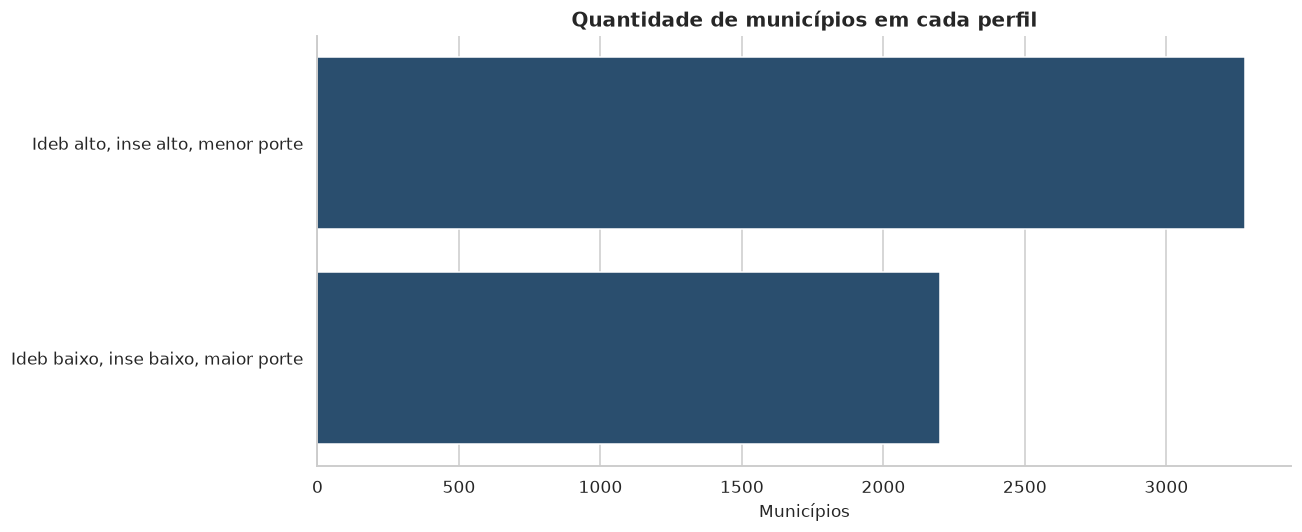

In [11]:
if "nome_regiao" in base.columns:
    composicao = pd.crosstab(
        base["perfil_municipal"],
        base["nome_regiao"],
        normalize="index",
    ).mul(100).round(1)
    composicao["municípios"] = base["perfil_municipal"].value_counts()
    display(composicao)

if "sigla_uf" in base.columns:
    por_uf = pd.crosstab(base["sigla_uf"], base["perfil_municipal"])
    display(por_uf)

fig, ax = plt.subplots(figsize=(12, 5))
ordem = base["perfil_municipal"].value_counts().index
sns.countplot(data=base, y="perfil_municipal", order=ordem, color=AZUL, ax=ax)
ax.set_xlabel("Municípios")
ax.set_ylabel("")
ax.set_title("Quantidade de municípios em cada perfil")
salvar_figura(fig, "07_tamanho_perfis")
plt.show()


##### 5. Cruzamento com o risco municipal


Tipos das chaves na base: {'id_municipio': <StringDtype(na_value=<NA>)>, 'rede': <StringDtype(na_value=<NA>)>}
Tipos das chaves no risco: {'id_municipio': <StringDtype(na_value=<NA>)>, 'rede': <StringDtype(na_value=<NA>)>}
Cobertura do cruzamento: 100.0%
{'both': 5477, 'left_only': 0, 'right_only': 0}


,municipios,risco_medio,em_risco_pct,cobertura_risco_pct
perfil_municipal,,,,
"Ideb baixo, inse baixo, maior porte",2199,0.43,41.52,100.0
"Ideb alto, inse alto, menor porte",3278,0.36,33.22,100.0


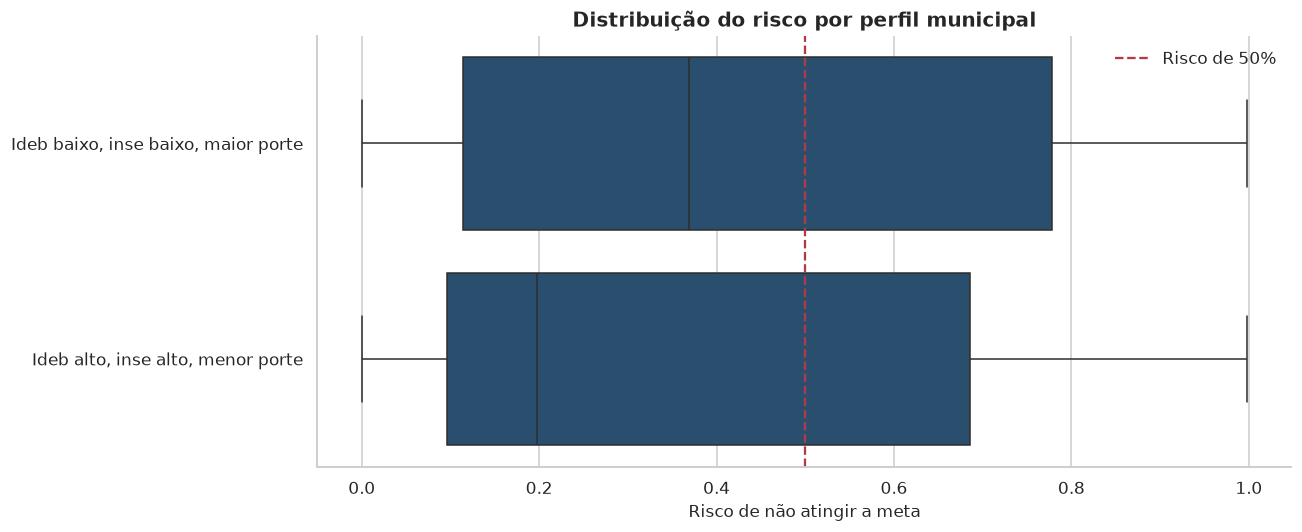

Relatório de risco utilizado: municipios_risco_2026.csv


In [12]:
# Localiza automaticamente o relatório de risco mais recente.
arquivos_risco = sorted(
    REPORTS.glob("municipios_risco_*.csv")
)

if not arquivos_risco:
    print(
        "Nenhum relatório municipios_risco_<ano>.csv "
        "foi encontrado. O cruzamento com risco foi ignorado."
    )

    base_risco = base.copy()
    coluna_risco = None

else:
    ARQ_RISCO = arquivos_risco[-1]

    # Lê o código municipal diretamente como texto.
    risco = pd.read_csv(
        ARQ_RISCO,
        dtype={
            "id_municipio": "string",
            "rede": "string",
        },
    )

    candidatos_risco = [
        "risco_nao_atingir",
        "risco_2026",
        "risco",
    ]

    coluna_risco = next(
        (
            coluna
            for coluna in candidatos_risco
            if coluna in risco.columns
        ),
        None,
    )

    if coluna_risco is None:
        raise KeyError(
            f"Coluna de risco não encontrada em "
            f"{ARQ_RISCO.name}. "
            f"Colunas disponíveis: {list(risco.columns)}"
        )

    # Padroniza o código municipal nos dois DataFrames.
    base["id_municipio"] = (
        base["id_municipio"]
        .astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.strip()
        .str.zfill(7)
    )

    risco["id_municipio"] = (
        risco["id_municipio"]
        .astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.strip()
        .str.zfill(7)
    )

    chaves = ["id_municipio"]

    # Inclui a rede somente quando existir nos dois arquivos.
    if (
        "rede" in base.columns
        and "rede" in risco.columns
    ):
        base["rede"] = (
            base["rede"]
            .astype("string")
            .str.lower()
            .str.strip()
        )

        risco["rede"] = (
            risco["rede"]
            .astype("string")
            .str.lower()
            .str.strip()
        )

        chaves.append("rede")

    risco[coluna_risco] = pd.to_numeric(
        risco[coluna_risco],
        errors="coerce",
    )

    risco_join = (
        risco[
            chaves
            + [coluna_risco]
        ]
        .dropna(
            subset=["id_municipio"]
        )
        .drop_duplicates(
            chaves,
            keep="last",
        )
    )

    print(
        "Tipos das chaves na base:",
        base[chaves].dtypes.to_dict(),
    )

    print(
        "Tipos das chaves no risco:",
        risco_join[chaves].dtypes.to_dict(),
    )

    base_risco = base.merge(
        risco_join,
        on=chaves,
        how="left",
        validate="one_to_one",
        indicator=True,
    )

    cobertura_merge = (
        100
        * base_risco["_merge"].eq("both").mean()
    )

    print(
        f"Cobertura do cruzamento: "
        f"{cobertura_merge:.1f}%"
    )

    print(
        base_risco["_merge"]
        .value_counts()
        .to_dict()
    )

    base_risco = base_risco.drop(
        columns="_merge"
    )

    matriz = (
        base_risco
        .groupby(
            "perfil_municipal",
            observed=True,
        )
        .agg(
            municipios=(
                "id_municipio",
                "nunique",
            ),
            risco_medio=(
                coluna_risco,
                "mean",
            ),
            em_risco=(
                coluna_risco,
                lambda serie: (
                    serie.dropna()
                    .ge(0.5)
                    .mean()
                ),
            ),
            cobertura_risco=(
                coluna_risco,
                lambda serie: (
                    serie.notna().mean()
                ),
            ),
        )
        .sort_values(
            "risco_medio",
            ascending=False,
        )
    )

    matriz["em_risco_pct"] = (
        100 * matriz.pop("em_risco")
    )

    matriz["cobertura_risco_pct"] = (
        100
        * matriz.pop("cobertura_risco")
    )

    display(
        matriz.round(2)
    )

    dados_grafico = base_risco.dropna(
        subset=[coluna_risco]
    )

    if dados_grafico.empty:
        print(
            "Não há valores de risco correspondentes "
            "para construir o gráfico."
        )

    else:
        fig, ax = plt.subplots(
            figsize=(12, 5)
        )

        ordem = matriz.index.tolist()

        sns.boxplot(
            data=dados_grafico,
            y="perfil_municipal",
            x=coluna_risco,
            order=ordem,
            color=AZUL,
            fliersize=2,
            ax=ax,
        )

        ax.axvline(
            0.5,
            color=VERMELHO,
            linestyle="--",
            label="Risco de 50%",
        )

        ax.set_xlabel(
            "Risco de não atingir a meta"
        )

        ax.set_ylabel("")

        ax.set_title(
            "Distribuição do risco por perfil municipal"
        )

        ax.legend()

        salvar_figura(
            fig,
            "07_perfil_x_risco",
        )

        plt.show()

    print(
        f"Relatório de risco utilizado: "
        f"{ARQ_RISCO.name}"
    )

##### 6. Entrega para o Tech Challenge


In [13]:
colunas_saida = [c for c in [
    "ano_alvo", "id_municipio", "nome_municipio", "sigla_uf", "nome_regiao", "rede",
    "segmento", "perfil_municipal", coluna_risco,
] if c is not None and c in base_risco.columns]

saida = base_risco[colunas_saida].copy()
ordenacao = [c for c in ["perfil_municipal", coluna_risco] if c is not None and c in saida.columns]
if ordenacao:
    ascending = [True] + ([False] if len(ordenacao) > 1 else [])
    saida = saida.sort_values(ordenacao, ascending=ascending)

saida.to_csv(REPORTS / "perfis_municipais_e_prioridades.csv", index=False, encoding="utf-8-sig")
saida.to_parquet(REPORTS / "perfis_municipais_e_prioridades.parquet", index=False)
catalogo_perfis.to_csv(REPORTS / "catalogo_perfis_municipais.csv", index=False, encoding="utf-8-sig")

print("Entregas salvas:")
print("- reports/perfis_municipais_e_prioridades.csv")
print("- reports/catalogo_perfis_municipais.csv")
display(saida.head(20))


Entregas salvas:
- reports/perfis_municipais_e_prioridades.csv
- reports/catalogo_perfis_municipais.csv


,ano_alvo,id_municipio,nome_municipio,sigla_uf,nome_regiao,rede,segmento,perfil_municipal,risco_nao_atingir
4735,2030,4310553,Itacurubi,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.998086
4679,2030,4307401,Esmeralda,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.998024
4895,2030,4317707,Santo Antônio das Missões,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.995863
4739,2030,4310702,Itatiba do Sul,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.995677
4929,2030,4319604,São Sepé,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.995430
4595,2030,4303400,Caiçara,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.994875
2389,2030,3116001,Chalé,MG,Sudeste,municipal,0,"Ideb alto, inse alto, menor porte",0.994813
4670,2030,4306924,Engenho Velho,RS,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.992899
4255,2030,4200309,Agronômica,SC,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.992837
4448,2030,4213708,Pouso Redondo,SC,Sul,municipal,0,"Ideb alto, inse alto, menor porte",0.992837


#### Resumo do Notebook 07 · Perfis Municipais e Prioridades

O notebook descreve os segmentos municipais formados no notebook anterior e cruza os perfis com o risco projetado de não atingir a meta. Foram analisados **5.477 municípios**, distribuídos em dois perfis.

##### Resultados numéricos

| Perfil | Municípios | Participação | Risco médio | Municípios com risco ≥ 50% |
|---|---:|---:|---:|---:|
| **IDEB alto, INSE alto e menor porte** | 3.278 | 60% | 0,36 | 33,2% |
| **IDEB baixo, INSE baixo e maior porte** | 2.199 | 40% | 0,43 | 41,5% |

A cobertura do cruzamento entre perfil e risco foi de **100%**.

###### Assinatura dos segmentos

O mapa de calor representa a mediana padronizada de cada variável em relação ao município típico. Valores positivos indicam características acima do padrão geral; valores negativos indicam características abaixo do padrão.

##### Segmento 0 · IDEB alto, INSE alto e menor porte

- IDEB, Português e Matemática: **+0,5 desvio-padrão**;
- rendimento e aprovação nos anos iniciais: **+0,6**;
- INSE médio: **+0,7**;
- PIB per capita: **+0,4**;
- população: **-0,1**;
- área territorial: **-0,3**;
- agropecuária no PIB: **-0,4**;
- administração pública e serviços no PIB: **-0,5**.

O perfil combina melhor desempenho educacional, condição socioeconômica mais favorável e maior PIB per capita, com municípios de menor porte relativo.

##### Segmento 1 · IDEB baixo, INSE baixo e maior porte

- IDEB e Matemática: **-0,9 desvio-padrão**;
- Português e PIB per capita: **-0,8**;
- INSE médio: **-0,9**;
- rendimento e aprovação geral: aproximadamente **-0,1**;
- área territorial: **+0,2**;
- aprovação no 1º e no 2º ano: **+0,3** e **+0,4**.

O perfil apresenta níveis educacionais e socioeconômicos inferiores ao padrão geral. A aprovação no 1º e no 2º ano permanece acima da média, mostrando que aprovação elevada não coincide necessariamente com IDEB e notas mais altas.

##### Características medianas

| Indicador | Perfil de melhor contexto | Perfil de maior vulnerabilidade |
|---|---:|---:|
| IDEB mais recente | 6,6 | 5,4 |
| Nota de Português | 226,1 | 198,8 |
| Nota de Matemática | 241,9 | 209,5 |
| INSE médio | 5,17 | 4,40 |
| PIB per capita | R$ 33.799 | R$ 13.556 |
| Densidade demográfica | 28,1 hab./km² | 19,2 hab./km² |
| População mediana | 10.676 | 12.251 |

##### Quantidade de municípios

O gráfico de barras confirma que os grupos possuem tamanhos diferentes, mas ambos são suficientemente grandes para análise:

- **3.278 municípios** no perfil de melhor contexto;
- **2.199 municípios** no perfil de maior vulnerabilidade;
- diferença de **1.079 municípios** entre os grupos.

A segmentação não criou um grupo residual muito pequeno. Isso favorece comparações e o planejamento de estratégias para conjuntos amplos de municípios.

##### Distribuição do risco por perfil

O boxplot mostra ampla dispersão do risco nos dois grupos, com valores que vão de aproximadamente **0 a 1**. Portanto, nenhum perfil é internamente homogêneo.

- No perfil de maior vulnerabilidade, a mediana visual do risco está próxima de **0,37** e o intervalo interquartil, aproximadamente entre **0,11 e 0,78**.
- No perfil de melhor contexto, a mediana visual está próxima de **0,20** e o intervalo interquartil, aproximadamente entre **0,10 e 0,69**.
- A linha de referência de **50%** atravessa as caixas dos dois perfis, confirmando que existem municípios prioritários em ambos os grupos.
- A distribuição do perfil de maior vulnerabilidade está deslocada para riscos mais altos, coerente com o risco médio de **0,43**, superior aos **0,36** do perfil de melhor contexto.

Os valores de mediana e quartis acima são leituras aproximadas do gráfico. Os valores exatos devem ser obtidos diretamente da tabela usada para gerar o boxplot.

##### Distribuição regional

- O perfil de melhor contexto concentra-se no **Sudeste, com 41%**, e no **Sul, com 33%**.
- O perfil de maior vulnerabilidade concentra-se no **Nordeste, com 63%**, e no **Norte, com 16%**.

A distribuição regional confirma concentração territorial, mas os perfis não devem ser interpretados como equivalentes às regiões. Municípios de uma mesma região podem pertencer a perfis diferentes.

##### Conclusões

- O perfil com **IDEB e INSE mais baixos** concentra maior risco: média de **0,43** e **41,5%** dos municípios acima do corte de 50%.
- O perfil de melhor contexto apresenta risco médio de **0,36**, mas ainda reúne **33,2%** dos municípios acima de 50% de risco.
- IDEB, notas de Português e Matemática, INSE e PIB per capita são os principais elementos que diferenciam os grupos.
- Aprovação elevada não garante, isoladamente, maiores notas ou IDEB, como mostra o Segmento 1.
- Existe grande heterogeneidade de risco dentro de cada perfil. O perfil ajuda a definir o tipo de intervenção, enquanto o ranking de risco ajuda a definir a prioridade.
- O risco foi aplicado somente depois da segmentação e não influenciou a formação dos grupos.
- Os segmentos representam padrões de semelhança, não relações causais nem categorias permanentes.

> **Síntese:** o perfil de IDEB baixo, INSE baixo e maior porte reúne maior vulnerabilidade média, mas há municípios de alto risco nos dois perfis. A melhor aplicação é combinar **perfil**, para orientar a estratégia de intervenção, com **risco individual do município**, para ordenar a prioridade de atendimento.

